In [1]:
# !pip install -q 'git+https://github.com/facebookresearch/segment-anything.git'
# !pip install -q jupyter_bbox_widget roboflow dataclasses-json supervision==0.23.0
# !mkdir -p {HOME}/weights
# !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth -P {HOME}/weights


# !mkdir -p {HOME}/data

# !wget -q https://media.roboflow.com/notebooks/examples/dog.jpeg -P {HOME}/data
# !wget -q https://media.roboflow.com/notebooks/examples/dog-2.jpeg -P {HOME}/data
# !wget -q https://media.roboflow.com/notebooks/examples/dog-3.jpeg -P {HOME}/data
# !wget -q https://media.roboflow.com/notebooks/examples/dog-4.jpeg -P {HOME}/data

In [1]:
import os
HOME = os.getcwd()
print("HOME:", HOME)

import os

CHECKPOINT_PATH = os.path.join(HOME, "weights", "sam_vit_h_4b8939.pth")
print(CHECKPOINT_PATH, "; exist:", os.path.isfile(CHECKPOINT_PATH))

import torch

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
MODEL_TYPE = "vit_h"
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH).to(device=DEVICE)

HOME: /Users/abedinm/01_PYTHON_CODE
/Users/abedinm/01_PYTHON_CODE/weights/sam_vit_h_4b8939.pth ; exist: True


In [33]:
import os

# IMAGE_NAME = "dog.jpeg"
IMAGE_PATH = 'task/samples/images/tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c.png'
# IMAGE_PATH = 'debug_bbox.jpg'
# helper function that loads an image before adding it to the widget

import base64

def encode_image(filepath):
    with open(filepath, 'rb') as f:
        image_bytes = f.read()
    encoded = str(base64.b64encode(image_bytes), 'utf-8')
    return "data:image/jpg;base64,"+encoded

In [34]:
from jupyter_bbox_widget import BBoxWidget

widget = BBoxWidget()
widget.image = encode_image(IMAGE_PATH)
widget

BBoxWidget(colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#b…

In [37]:
import numpy as np

# default_box is going to be used if you will not draw any box on image above
default_box = widget.bboxes

box = widget.bboxes[0] if widget.bboxes else default_box
box = np.array([
    box['x'],
    box['y'],
    box['x'] + box['width'],
    box['y'] + box['height']
])

In [38]:
import cv2
import numpy as np
import supervision as sv

mask_predictor = SamPredictor(sam)
image_bgr = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

mask_predictor.set_image(image_rgb)

masks, scores, logits = mask_predictor.predict(
    box=box,
    multimask_output=True
)

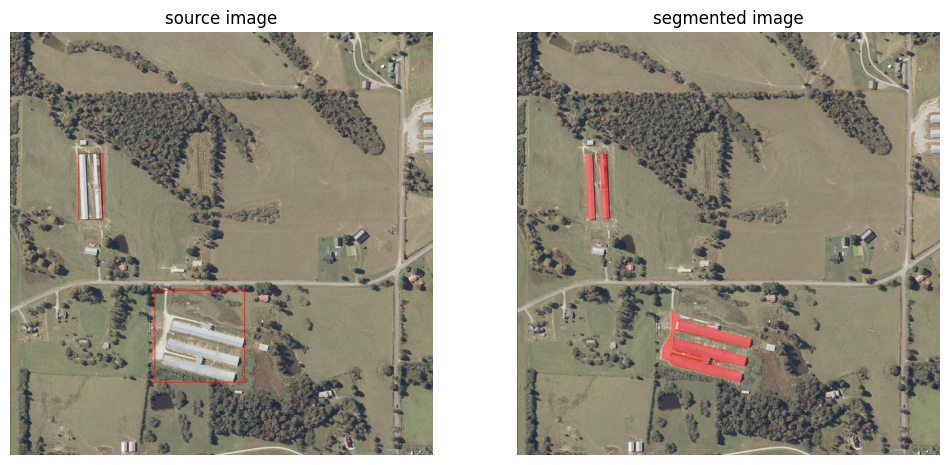

True

In [39]:
import numpy as np
# Get all bounding boxes
boxes = widget.bboxes if widget.bboxes else [default_box]

all_masks = []
all_scores = []
all_logits = []
all_xyxy = []

for box in boxes:
    np_box = np.array([
        box['x'],
        box['y'],
        box['x'] + box['width'],
        box['y'] + box['height']
    ])
    masks, scores, logits = mask_predictor.predict(
        box=np_box,
        multimask_output=True
    )
    # Take best mask (highest score)
    best_idx = np.argmax(scores)
    all_masks.append(masks[best_idx])
    all_scores.append(scores[best_idx])
    all_logits.append(logits[best_idx])
    all_xyxy.append(sv.mask_to_xyxy(masks=masks[best_idx][None, ...])[0])

all_masks = np.stack(all_masks)
all_xyxy = np.stack(all_xyxy)

# Prepare detections for supervision
detections = sv.Detections(
    xyxy=all_xyxy,
    mask=all_masks
)

# Draw all boxes and masks
box_annotator = sv.BoxAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)
mask_annotator = sv.MaskAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)

source_image = box_annotator.annotate(scene=image_bgr.copy(), detections=detections)
segmented_image = mask_annotator.annotate(scene=image_bgr.copy(), detections=detections)

sv.plot_images_grid(
    images=[source_image, segmented_image],
    grid_size=(1, 2),
    titles=['source image', 'segmented image']
)

# Save as PNG
output_path = "segmented_overlay.png"
cv2.imwrite(output_path, segmented_image)
# print(f"Saved segmented image to {output_path}")Saved segmented image to segmented_overlay.png

In [45]:
widget.bboxes

[{'x': 316, 'y': 582, 'width': 73, 'height': 349, 'label': ''},
 {'x': 393, 'y': 580, 'width': 67, 'height': 340, 'label': ''}]

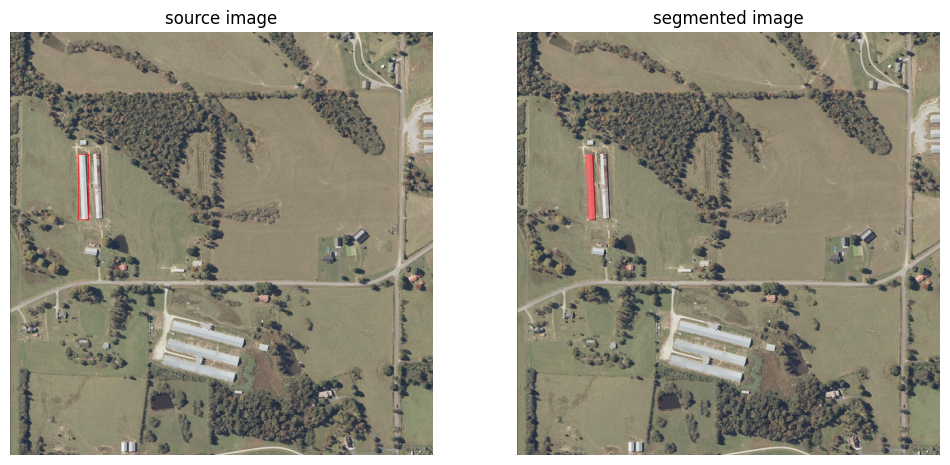

In [52]:
box_annotator = sv.BoxAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)
mask_annotator = sv.MaskAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)

detections = sv.Detections(
    xyxy=sv.mask_to_xyxy(masks=masks),
    mask=masks
)
detections = detections[detections.area == np.max(detections.area)]

source_image = box_annotator.annotate(scene=image_bgr.copy(), detections=detections)
segmented_image = mask_annotator.annotate(scene=image_bgr.copy(), detections=detections)

sv.plot_images_grid(
    images=[source_image, segmented_image],
    grid_size=(1, 2),
    titles=['source image', 'segmented image']
)

final text_encoder_type: bert-base-uncased


Saved: grounded_sam_text_prompted_output.png


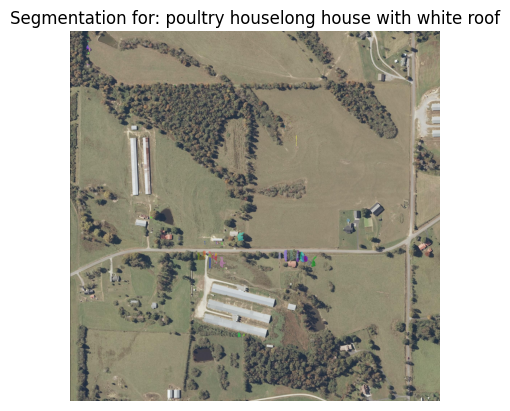

In [30]:
import os
import torch
import cv2
import numpy as np

from segment_anything import SamPredictor, sam_model_registry

#################
import torch
import numpy as np
import cv2
import importlib.util

def get_grounding_output(model, image, caption, box_threshold, text_threshold):
    from groundingdino.util.inference import predict
    import torch
    h, w = image.shape[:2]
    if isinstance(image, np.ndarray):
        image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
    else:
        image_tensor = image
    boxes, logits, phrases = predict(
        model=model,
        image=image_tensor,
        caption=caption,
        box_threshold=box_threshold,
        text_threshold=text_threshold,
        device="cpu"
    )
    boxes = boxes * torch.tensor([w, h, w, h], dtype=boxes.dtype)
    boxes = boxes.int().cpu().numpy()
    return boxes, logits, phrases



def run_sam(image, boxes, predictor):
    predictor.set_image(image)
    transformed_boxes = predictor.transform.apply_boxes_torch(
        torch.tensor(boxes, dtype=torch.float, device=predictor.device),
        image.shape[:2]
    )
    masks, _, _ = predictor.predict_torch(
        point_coords=None,
        point_labels=None,
        boxes=transformed_boxes,
        multimask_output=False
    )
    masks = masks.cpu().numpy()
    # Assume masks.shape == (N, H, W)
    return masks > 0.0

def load_model(config_path, checkpoint_path):
    import importlib.util
    spec = importlib.util.spec_from_file_location("GroundingDINOConfig", config_path)
    config_module = spec.loader.load_module()
    if hasattr(config_module, "get_cfg"):
        config = config_module.get_cfg()
    else:
        raise AttributeError(f"No 'get_cfg()' found in {config_path}. Use a config file with get_cfg().")
    from groundingdino.models import build_model
    model = build_model(config)
    checkpoint = torch.load(checkpoint_path, map_location="cpu")
    model.load_state_dict(checkpoint["model"], strict=False)
    model.eval()
    # model.cuda()
    model.cpu()
    return model


##############################

# ==== Paths ====
image_path = 'task/samples/images/tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c.png'  # <-- Set your image path here!
sam_checkpoint = "weights/sam_vit_h_4b8939.pth"
groundingdino_config = "Grounded-Segment-Anything/GroundingDINO/groundingdino/config/GroundingDINO_SwinT_OGC.py"
groundingdino_checkpoint = "weights/groundingdino_swint_ogc.pth"

# ==== Text Prompt ====
text_prompt = "poultry house-long house with white roof"   # e.g., "dog", "car", etc.

# ==== Load Image ====
image_source = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image_source, cv2.COLOR_BGR2RGB)

# ==== Load Models ====
# Load GroundingDINO
groundingdino_model = load_model(
    groundingdino_config,
    groundingdino_checkpoint
)

# Load SAM
sam = sam_model_registry["vit_h"](checkpoint=sam_checkpoint)
sam_predictor = SamPredictor(sam)

# ==== Get boxes for the text prompt ====
boxes, logits, phrases = get_grounding_output(
    model=groundingdino_model,
    image=image_source,
    caption=text_prompt,
    box_threshold=0.5,
    text_threshold=0.5
)

if len(boxes) == 0:
    print("No detections found for prompt:", text_prompt)
    exit()

# ==== Run SAM on the detected boxes ====
masks = run_sam(
    image=image_source,
    boxes=boxes,
    predictor=sam_predictor
)

# ==== Overlay Masks on Image ====
overlay = image_source.copy()
for mask in masks:
    if mask.ndim == 3 and mask.shape[0] == 1:
        mask = mask[0]
    elif mask.ndim == 3 and mask.shape[0] > 1:
        # If multiple masks in one, you may want to select one or iterate
        mask = mask[0]
    mask = mask.astype(bool)
    color = np.random.randint(0, 255, (3,), dtype=np.uint8)
    overlay[mask] = overlay[mask] * 0.5 + color * 0.5


cv2.imwrite("grounded_sam_text_prompted_output.png", overlay)
print("Saved:", "grounded_sam_text_prompted_output.png")

# ==== Optionally, display (requires matplotlib) ====
import matplotlib.pyplot as plt
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title(f"Segmentation for: {text_prompt}")
plt.axis("off")
plt.show()
